Available rise angle columns: 6
Available decay angle columns: 6

  1. MEAN DIRECTION PER REGION (all drug cases)

  RISE phase:
    Top-L   : mean =  240.4° ±  28.9°  (n=30)
    Top-R   : mean =  259.4° ±  37.7°  (n=30)
    Mid-L   : mean =  188.2° ±  37.0°  (n=30)
    Mid-R   : mean =   31.0° ±  85.0°  (n=30)
    Bot-L   : mean =  138.8° ±  23.5°  (n=30)
    Bot-R   : mean =   53.3° ±  41.2°  (n=30)

  DECAY phase:
    Top-L   : mean =   53.3° ±  27.8°  (n=30)
    Top-R   : mean =   96.8° ±  40.1°  (n=30)
    Mid-L   : mean =    2.1° ±  34.5°  (n=30)
    Mid-R   : mean =  201.8° ±  48.1°  (n=30)
    Bot-L   : mean =  323.3° ±  21.3°  (n=30)
    Bot-R   : mean =  212.6° ±  31.2°  (n=30)

  2. DIRECTION vs CONCENTRATION

  RISE phase:

    Verapamil:
        0.02 μM:  218.4° ±  54.3°  (n=3)
        0.10 μM:  201.9° ±  40.1°  (n=3)
        0.50 μM:  205.5° ±  37.2°  (n=3)
        1.00 μM:  144.6° ±  76.0°  (n=3)
       10.00 μM:  200.1° ±  36.4°  (n=3)
      Angular spread vs dose: r = 

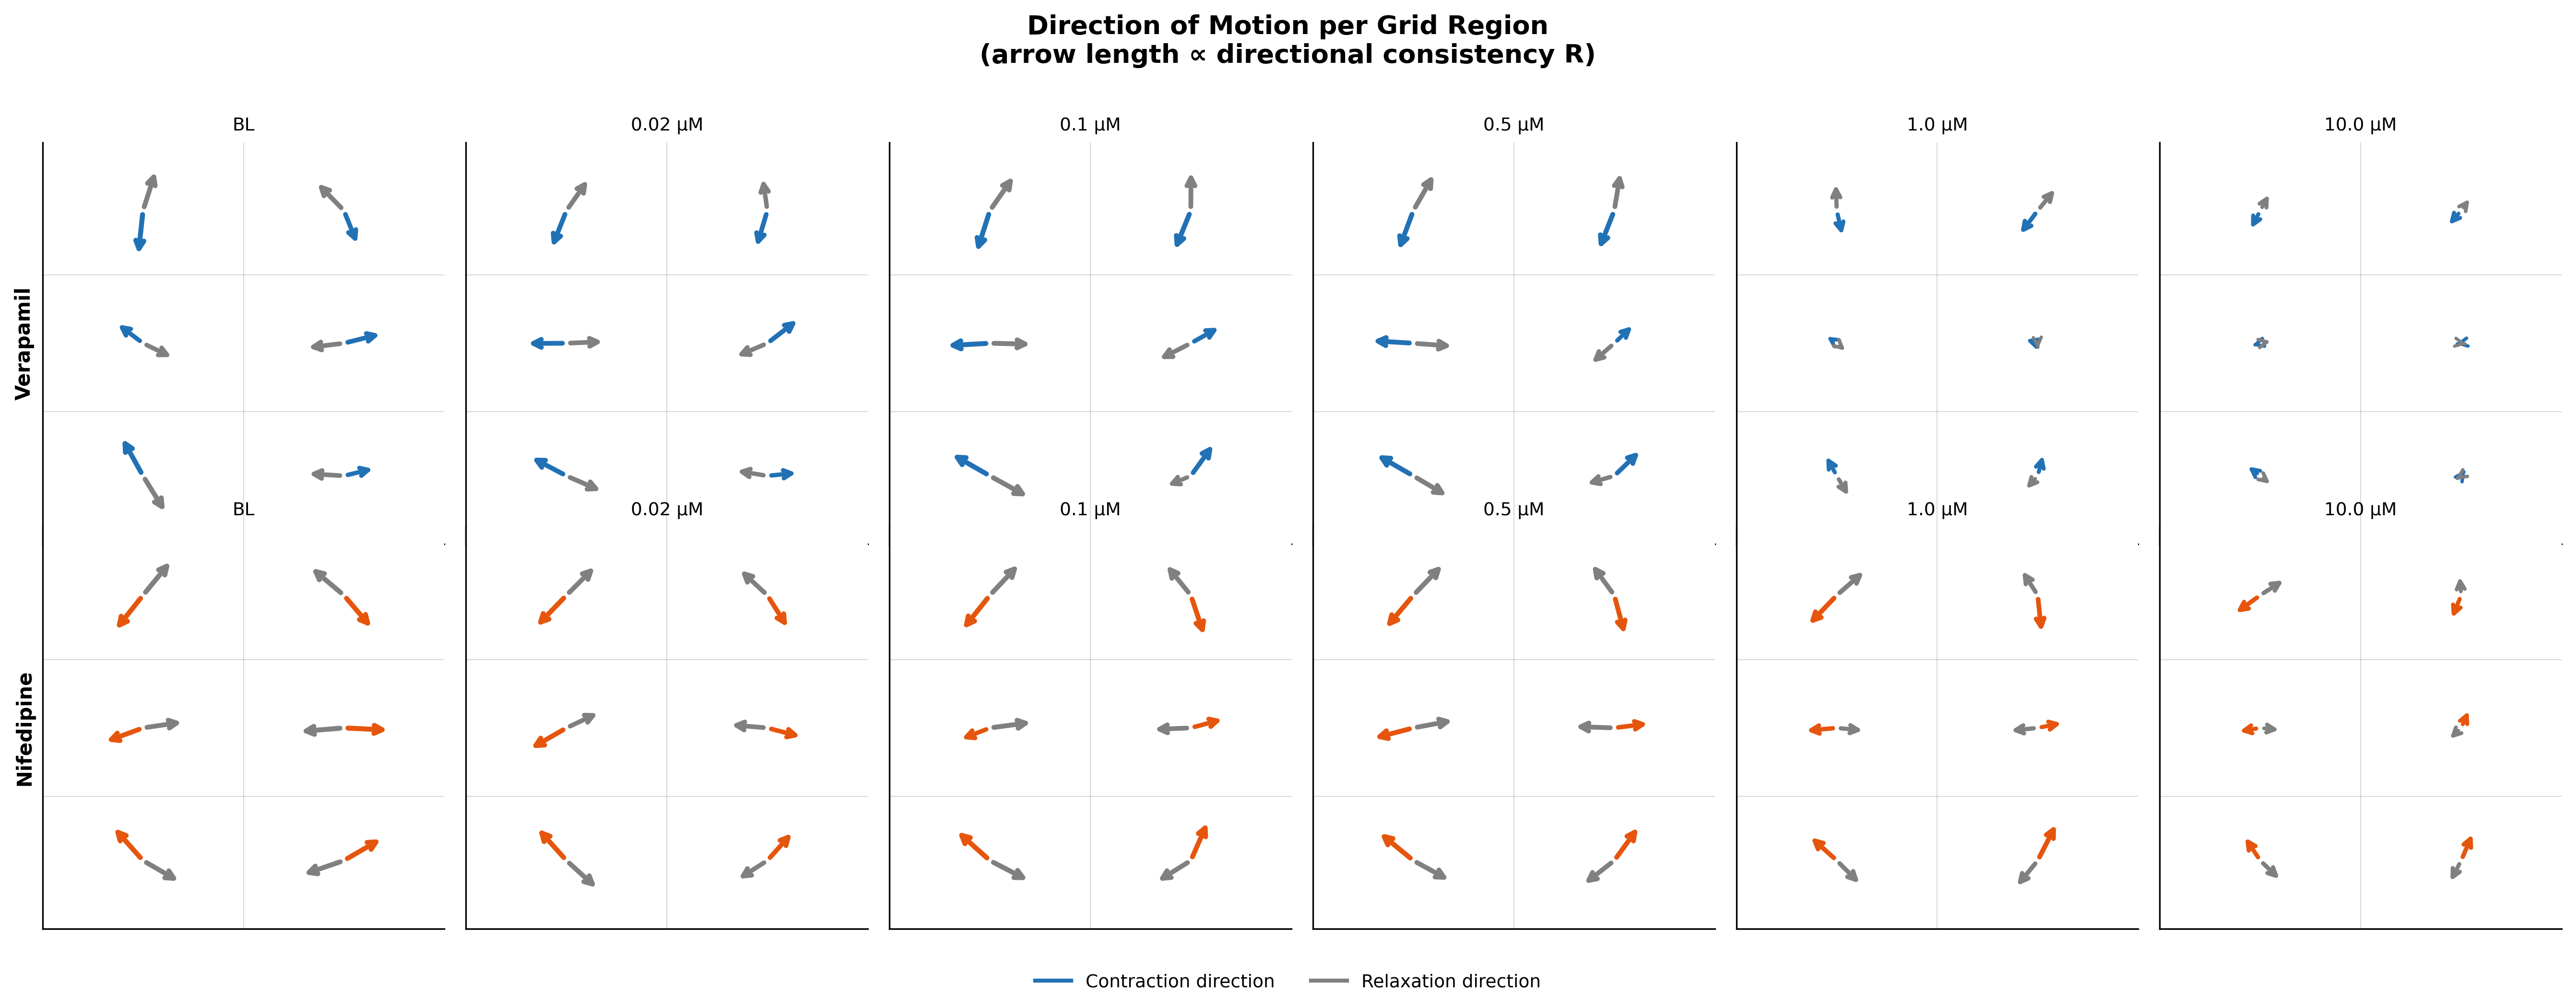

Saved: fig_direction_arrows.png/pdf

  SUMMARY

This analysis answers:
1. What direction does each tissue region move during contraction/relaxation?
2. Does direction change with drug concentration?
3. Are contraction and relaxation directions opposite?
4. Does within-tissue directional consistency change with dose?

Key: All angles are computed using circular statistics (no wrapping artifacts).
Arrow figure shows mean direction per condition — arrow length = R (consistency).

If results are interesting → include as supplementary figure.
If direction doesn't change much → mention in text only.



In [ ]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.spines.top': False,
    'axes.spines.right': False,
})

VERA = '#2171B5'
NIFE = '#E6550D'

CSV_PATH = "/raid/.../all_results.csv"
df = pd.read_csv(CSV_PATH)

# ──────────────────────────────────────────────
# Circular statistics helpers
# ──────────────────────────────────────────────
def circ_mean_deg(angles_deg):
    """Circular mean of angles in degrees. Returns 0-360."""
    angles_deg = np.array(angles_deg, dtype=np.float64)
    rad = np.radians(angles_deg)
    s = np.nanmean(np.sin(rad))
    c = np.nanmean(np.cos(rad))
    return np.degrees(np.arctan2(s, c)) % 360

def circ_std_deg(angles_deg):
    """Circular standard deviation in degrees."""
    angles_deg = np.array(angles_deg, dtype=np.float64)
    rad = np.radians(angles_deg)
    R = np.sqrt(np.nanmean(np.cos(rad))**2 + np.nanmean(np.sin(rad))**2)
    if R > 1: R = 1.0
    if R < 1e-10: return 180.0
    return np.degrees(np.sqrt(-2 * np.log(R)))

def angle_diff(a1, a2):
    """Shortest angular difference in degrees (-180 to 180)."""
    d = (a1 - a2 + 180) % 360 - 180
    return d

# ──────────────────────────────────────────────
# Extract angle columns
# ──────────────────────────────────────────────
regions = ['r0c0', 'r0c1', 'r1c0', 'r1c1', 'r2c0', 'r2c1']
region_names = ['Top-L', 'Top-R', 'Mid-L', 'Mid-R', 'Bot-L', 'Bot-R']

# Check which angle columns exist
angle_cols_rise = [f"{r}_rise_angle" for r in regions]
angle_cols_decay = [f"{r}_decay_angle" for r in regions]

available_rise = [c for c in angle_cols_rise if c in df.columns]
available_decay = [c for c in angle_cols_decay if c in df.columns]

print(f"Available rise angle columns: {len(available_rise)}")
print(f"Available decay angle columns: {len(available_decay)}")

if not available_rise:
    # Try alternative column names
    print("\nLooking for alternative angle column names...")
    angle_candidates = [c for c in df.columns if 'angle' in c.lower()]
    print(f"Found: {angle_candidates}")
    if not angle_candidates:
        print("No angle data in CSV. Need to re-extract from pipeline.")
        exit()

# ──────────────────────────────────────────────
# Prepare data
# ──────────────────────────────────────────────
df_conc = df[(df['conc'].notna()) & (df['conc'] > 0)].copy()
df_baseline = df[df['conc'] == 0].copy()

# Compute per-case mean direction (circular mean of 6 cells)
for phase, cols in [('rise', available_rise), ('decay', available_decay)]:
    if cols:
        def row_circ_mean(row):
            vals = row[cols].dropna().values
            if len(vals) == 0:
                return np.nan
            return circ_mean_deg(vals)
        
        def row_circ_std(row):
            vals = row[cols].dropna().values
            if len(vals) < 2:
                return np.nan
            return circ_std_deg(vals)
        
        df[f'mean_{phase}_angle'] = df.apply(row_circ_mean, axis=1)
        df[f'{phase}_angle_spread'] = df.apply(row_circ_std, axis=1)
        df_conc[f'mean_{phase}_angle'] = df_conc.apply(row_circ_mean, axis=1)
        df_conc[f'{phase}_angle_spread'] = df_conc.apply(row_circ_std, axis=1)


# ══════════════════════════════════════════════
# ANALYSIS 1: What direction does each region move?
# ══════════════════════════════════════════════
print("\n" + "=" * 70)
print("  1. MEAN DIRECTION PER REGION (all drug cases)")
print("=" * 70)

for phase, cols in [('rise', available_rise), ('decay', available_decay)]:
    if not cols:
        continue
    print(f"\n  {phase.upper()} phase:")
    for col, name in zip(cols, region_names[:len(cols)]):
        vals = df_conc[col].dropna().values
        if len(vals) == 0:
            continue
        m = circ_mean_deg(vals)
        s = circ_std_deg(vals)
        print(f"    {name:8s}: mean = {m:6.1f}° ± {s:5.1f}°  (n={len(vals)})")


# ══════════════════════════════════════════════
# ANALYSIS 2: Does direction change with concentration?
# ══════════════════════════════════════════════
print("\n" + "=" * 70)
print("  2. DIRECTION vs CONCENTRATION")
print("=" * 70)

for phase in ['rise', 'decay']:
    angle_col = f'mean_{phase}_angle'
    if angle_col not in df_conc.columns:
        continue
    
    print(f"\n  {phase.upper()} phase:")
    for drug in ['verapamil', 'nifedipine']:
        sub = df_conc[df_conc['drug'] == drug].dropna(subset=[angle_col])
        if len(sub) < 4:
            continue
        
        concs = sorted(sub['conc'].unique())
        print(f"\n    {drug.capitalize()}:")
        for c in concs:
            vals = sub[sub['conc'] == c][angle_col].dropna().values
            if len(vals) > 0:
                m = circ_mean_deg(vals)
                s = circ_std_deg(vals) if len(vals) > 1 else 0
                print(f"      {c:6.2f} μM: {m:6.1f}° ± {s:5.1f}°  (n={len(vals)})")
        
        # Does spread (angular consistency) change with dose?
        spread_col = f'{phase}_angle_spread'
        if spread_col in df_conc.columns:
            sub2 = sub.dropna(subset=[spread_col])
            if len(sub2) >= 4:
                r, p = stats.spearmanr(np.log10(sub2['conc']), sub2[spread_col])
                sig = '*' if p < 0.05 else ''
                print(f"      Angular spread vs dose: r = {r:.2f}, p = {p:.3f}{sig}")


# ══════════════════════════════════════════════
# ANALYSIS 3: Rise vs Decay direction difference
# ══════════════════════════════════════════════
print("\n" + "=" * 70)
print("  3. CONTRACTION vs RELAXATION DIRECTION")
print("=" * 70)

if 'mean_rise_angle' in df_conc.columns and 'mean_decay_angle' in df_conc.columns:
    valid = df_conc[['mean_rise_angle', 'mean_decay_angle']].dropna()
    diffs = [abs(angle_diff(r, d)) for r, d in zip(valid['mean_rise_angle'], valid['mean_decay_angle'])]
    
    print(f"  Angle difference (rise vs decay):")
    print(f"    Mean:   {np.mean(diffs):.1f}°")
    print(f"    Median: {np.median(diffs):.1f}°")
    print(f"    Range:  {np.min(diffs):.1f}° – {np.max(diffs):.1f}°")
    
    n_opposite = sum(1 for d in diffs if d > 135)
    print(f"    Cases with near-opposite direction (>135°): {n_opposite}/{len(diffs)}")
    print(f"    → {'YES' if n_opposite > len(diffs)*0.8 else 'NO'}: rise and decay are consistently opposite")


# ══════════════════════════════════════════════
# ANALYSIS 4: Intra-tissue direction consistency
# ══════════════════════════════════════════════
print("\n" + "=" * 70)
print("  4. WITHIN-TISSUE DIRECTION CONSISTENCY")
print("=" * 70)

for phase, cols in [('rise', available_rise), ('decay', available_decay)]:
    if not cols or len(cols) < 2:
        continue
    
    spread_col = f'{phase}_angle_spread'
    if spread_col not in df_conc.columns:
        continue
    
    print(f"\n  {phase.upper()} phase - angular spread across 6 regions:")
    for drug in ['verapamil', 'nifedipine']:
        sub = df_conc[df_conc['drug'] == drug].dropna(subset=[spread_col])
        print(f"    {drug.capitalize()}: mean spread = {sub[spread_col].mean():.1f}° ± {sub[spread_col].std():.1f}°")
        
        # Does consistency change with dose?
        if len(sub) >= 4:
            r, p = stats.spearmanr(np.log10(sub['conc']), sub[spread_col])
            sig = '*' if p < 0.05 else ''
            direction = "more consistent" if r < 0 else "less consistent"
            print(f"    Spread vs dose: r = {r:.2f}, p = {p:.3f}{sig} → higher dose = {direction}")


# ══════════════════════════════════════════════
# FIGURE: Direction arrows on grid (per drug × conc)
# ══════════════════════════════════════════════
print("\n\nCreating direction figure...")

fig, axes = plt.subplots(2, 6, figsize=(18, 7))

conc_values = sorted(df_conc['conc'].unique())
grid_positions = {
    'r0c0': (0.25, 0.83), 'r0c1': (0.75, 0.83),
    'r1c0': (0.25, 0.50), 'r1c1': (0.75, 0.50),
    'r2c0': (0.25, 0.17), 'r2c1': (0.75, 0.17),
}

for drug_idx, (drug, color) in enumerate([('verapamil', VERA), ('nifedipine', NIFE)]):
    # First column: baseline
    ax = axes[drug_idx, 0]
    prefix = 'V' if drug == 'verapamil' else 'N'
    bl = df_baseline[df_baseline['case_name'].str.startswith(prefix)]
    
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_aspect('equal')
    ax.set_title('BASE', fontsize=9)
    if drug_idx == 0:
        ax.set_ylabel('Verapamil', fontweight='bold')
    else:
        ax.set_ylabel('Nifedipine', fontweight='bold')
    
    # Draw grid lines
    ax.axhline(0.33, color='gray', alpha=0.3, linewidth=0.5)
    ax.axhline(0.67, color='gray', alpha=0.3, linewidth=0.5)
    ax.axvline(0.5, color='gray', alpha=0.3, linewidth=0.5)
    ax.set_xticks([])
    ax.set_yticks([])
    
    for phase_name, phase_cols, arrow_color in [('rise', available_rise, color), ('decay', available_decay, 'gray')]:
        for col, (region, (gx, gy)) in zip(phase_cols, grid_positions.items()):
            vals = bl[col].dropna().values
            if len(vals) == 0:
                continue
            mean_angle = circ_mean_deg(vals)
            
            # R value for arrow length
            R_col = f"{region}_{phase_name}_R"
            R_val = bl[R_col].mean() if R_col in bl.columns else 0.5
            
            rad = np.radians(mean_angle)
            arrow_len = 0.12 * R_val
            dx = arrow_len * np.cos(rad)
            dy = arrow_len * np.sin(rad)
            
            ax.annotate('', xy=(gx + dx, gy + dy), xytext=(gx, gy),
                        arrowprops=dict(arrowstyle='->', color=arrow_color,
                                       lw=1.5 + R_val))
    
    # Concentration columns
    for conc_idx, conc in enumerate(conc_values):
        ax = axes[drug_idx, conc_idx + 1]
        sub = df_conc[(df_conc['drug'] == drug) & (df_conc['conc'] == conc)]
        
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal')
        ax.set_title(f'{conc} μM', fontsize=9)
        ax.axhline(0.33, color='gray', alpha=0.3, linewidth=0.5)
        ax.axhline(0.67, color='gray', alpha=0.3, linewidth=0.5)
        ax.axvline(0.5, color='gray', alpha=0.3, linewidth=0.5)
        ax.set_xticks([])
        ax.set_yticks([])
        
        if conc_idx + 1 < len(conc_values):
            pass  # only label first column
        
        for phase_name, phase_cols, arrow_color in [('rise', available_rise, color), ('decay', available_decay, 'gray')]:
            for col, (region, (gx, gy)) in zip(phase_cols, grid_positions.items()):
                vals = sub[col].dropna().values
                if len(vals) == 0:
                    continue
                mean_angle = circ_mean_deg(vals)
                
                R_col = f"{region}_{phase_name}_R"
                R_val = sub[R_col].mean() if R_col in sub.columns else 0.5
                
                rad = np.radians(mean_angle)
                arrow_len = 0.12 * R_val
                dx = arrow_len * np.cos(rad)
                dy = arrow_len * np.sin(rad)
                
                ax.annotate('', xy=(gx + dx, gy + dy), xytext=(gx, gy),
                            arrowprops=dict(arrowstyle='->', color=arrow_color,
                                           lw=1.5 + R_val))

# Legend
from matplotlib.lines import Line2D
fig.legend(handles=[
    Line2D([0], [0], color=VERA, lw=2, label='Contraction direction'),
    Line2D([0], [0], color='gray', lw=2, label='Relaxation direction'),
], loc='lower center', ncol=2, fontsize=9, frameon=False)

plt.suptitle('Direction of Motion per Grid Region\n(arrow length ∝ directional consistency R)',
             fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.savefig("fig_direction_arrows.png", dpi=300)
plt.savefig("fig_direction_arrows.pdf")
plt.show()
print("Saved: fig_direction_arrows.png/pdf")


# ══════════════════════════════════════════════
# SUMMARY
# ══════════════════════════════════════════════
print("\n" + "=" * 70)
print("  SUMMARY")
print("=" * 70)
print("""
This analysis answers:
1. What direction does each tissue region move during contraction/relaxation?
2. Does direction change with drug concentration?
3. Are contraction and relaxation directions opposite?
4. Does within-tissue directional consistency change with dose?

Key: All angles are computed using circular statistics (no wrapping artifacts).
Arrow figure shows mean direction per condition — arrow length = R (consistency).

If results are interesting → include as supplementary figure.
If direction doesn't change much → mention in text only.
""")

In [ ]:
#!/usr/bin/env python3
"""Direction analysis - AGE component. Run after direction_analysis.py"""
import pandas as pd
import numpy as np
from scipy import stats

CSV_PATH = "/raid/.../all_results.csv"
df = pd.read_csv(CSV_PATH)

regions = ['r0c0', 'r0c1', 'r1c0', 'r1c1', 'r2c0', 'r2c1']
region_names = ['Top-L', 'Top-R', 'Mid-L', 'Mid-R', 'Bot-L', 'Bot-R']

def circ_mean_deg(angles_deg):
    angles_deg = np.array(angles_deg, dtype=np.float64)
    rad = np.radians(angles_deg)
    s = np.nanmean(np.sin(rad))
    c = np.nanmean(np.cos(rad))
    return np.degrees(np.arctan2(s, c)) % 360

def circ_std_deg(angles_deg):
    angles_deg = np.array(angles_deg, dtype=np.float64)
    rad = np.radians(angles_deg)
    R = np.sqrt(np.nanmean(np.cos(rad))**2 + np.nanmean(np.sin(rad))**2)
    if R > 1: R = 1.0
    if R < 1e-10: return 180.0
    return np.degrees(np.sqrt(-2 * np.log(R)))

# Age subset
df_age = df[df['age'].notna()].copy()
print(f"Age cases: {len(df_age)}")
print(f"Ages: {sorted(df_age['age'].unique())}")

if len(df_age) < 4:
    print("Not enough age data.")
    exit()

# Compute angular spread per case
for phase in ['rise', 'decay']:
    cols = [f"{r}_{phase}_angle" for r in regions]
    cols = [c for c in cols if c in df_age.columns]
    
    if not cols:
        continue
    
    spreads = []
    means = []
    for _, row in df_age.iterrows():
        vals = row[cols].dropna().values
        vals = np.array(vals, dtype=np.float64)
        if len(vals) >= 2:
            spreads.append(circ_std_deg(vals))
            means.append(circ_mean_deg(vals))
        else:
            spreads.append(np.nan)
            means.append(np.nan)
    
    df_age[f'{phase}_angle_spread'] = spreads
    df_age[f'mean_{phase}_angle'] = means

print("\n" + "=" * 70)
print("  DIRECTION vs AGE (maturation)")
print("=" * 70)

for phase in ['rise', 'decay']:
    spread_col = f'{phase}_angle_spread'
    angle_col = f'mean_{phase}_angle'
    
    if spread_col not in df_age.columns:
        continue
    
    print(f"\n  {phase.upper()} phase:")
    
    ages = sorted(df_age['age'].unique())
    for age in ages:
        sub = df_age[df_age['age'] == age]
        vals = sub[spread_col].dropna().values
        if len(vals) > 0:
            print(f"    Day {int(age):2d}: spread = {np.mean(vals):5.1f}° ± {np.std(vals):5.1f}°  "
                  f"mean dir = {circ_mean_deg(sub[angle_col].dropna().values):5.1f}°  (n={len(vals)})")
    
    # Correlation: age vs angular spread
    valid = df_age[[spread_col, 'age']].dropna()
    if len(valid) >= 4:
        r, p = stats.spearmanr(valid['age'], valid[spread_col])
        sig = '*' if p < 0.05 else ''
        direction = "more consistent" if r < 0 else "less consistent"
        print(f"    Age vs spread: r = {r:.2f}, p = {p:.3f}{sig} → older = {direction}")

# Per-region: does R change with age?
print("\n" + "=" * 70)
print("  R (directional consistency) vs AGE per region")
print("=" * 70)

for phase in ['rise', 'decay']:
    print(f"\n  {phase.upper()} phase:")
    for region, name in zip(regions, region_names):
        R_col = f"{region}_{phase}_R"
        if R_col not in df_age.columns:
            continue
        valid = df_age[['age', R_col]].dropna()
        if len(valid) >= 4:
            r, p = stats.spearmanr(valid['age'], valid[R_col])
            sig = '*' if p < 0.05 else ''
            print(f"    {name:8s}: r = {r:+.2f}, p = {p:.3f}{sig}")

# Drug-specific age effects
print("\n" + "=" * 70)
print("  DIRECTION SPREAD vs AGE by DRUG")
print("=" * 70)

for drug in df_age['drug'].dropna().unique():
    sub = df_age[df_age['drug'] == drug]
    if len(sub) < 4:
        continue
    print(f"\n  {drug.capitalize()} (n={len(sub)}):")
    for phase in ['rise', 'decay']:
        spread_col = f'{phase}_angle_spread'
        if spread_col not in sub.columns:
            continue
        valid = sub[['age', spread_col]].dropna()
        if len(valid) >= 4:
            r, p = stats.spearmanr(valid['age'], valid[spread_col])
            sig = '*' if p < 0.05 else ''
            print(f"    {phase}: spread vs age r = {r:.2f}, p = {p:.3f}{sig}")

Age cases: 30
Ages: [np.float64(11.0), np.float64(15.0), np.float64(19.0), np.float64(23.0), np.float64(27.0)]

  DIRECTION vs AGE (maturation)

  RISE phase:
    Day 11: spread =  82.6° ±  28.3°  mean dir = 139.6°  (n=6)
    Day 15: spread =  86.8° ±  16.5°  mean dir = 143.7°  (n=6)
    Day 19: spread = 106.3° ±  32.4°  mean dir = 173.5°  (n=6)
    Day 23: spread = 115.6° ±  14.6°  mean dir = 171.4°  (n=6)
    Day 27: spread = 118.9° ±  22.8°  mean dir = 200.7°  (n=6)
    Age vs spread: r = 0.54, p = 0.002* → older = less consistent

  DECAY phase:
    Day 11: spread =  92.9° ±  24.3°  mean dir = 323.7°  (n=6)
    Day 15: spread = 108.0° ±  16.1°  mean dir = 313.7°  (n=6)
    Day 19: spread = 106.3° ±  26.1°  mean dir = 358.0°  (n=6)
    Day 23: spread = 126.2° ±  13.1°  mean dir = 344.7°  (n=6)
    Day 27: spread = 116.0° ±  11.8°  mean dir =  11.8°  (n=6)
    Age vs spread: r = 0.41, p = 0.025* → older = less consistent

  R (directional consistency) vs AGE per region

  RISE phase:

In [ ]:
#!/usr/bin/env python3
"""Quick age analysis - velocity + direction for paper inclusion."""
import pandas as pd
import numpy as np
from scipy import stats

CSV_PATH = "/raid/.../all_results.csv"
df = pd.read_csv(CSV_PATH)

regions = ['r0c0', 'r0c1', 'r1c0', 'r1c1', 'r2c0', 'r2c1']

for phase in ['rise', 'decay']:
    vel_cols = [f"r{r}c{c}_{phase}_vel_mm_s" for r in range(3) for c in range(2)]
    vel_cols = [c for c in vel_cols if c in df.columns]
    df[f'mean_{phase}_vel'] = df[vel_cols].mean(axis=1)

df['vel_ratio'] = df['mean_rise_vel'] / df['mean_decay_vel'].replace(0, np.nan)

df_age = df[df['age'].notna()].copy()
print(f"Age cases: {len(df_age)}")
print(f"Ages: {sorted(df_age['age'].unique())}\n")

print("=" * 60)
print("  VELOCITY vs AGE")
print("=" * 60)

for col, label in [('mean_rise_vel', 'Contraction vel'), 
                    ('mean_decay_vel', 'Relaxation vel'),
                    ('vel_ratio', 'Velocity ratio')]:
    valid = df_age[['age', col]].dropna()
    if len(valid) >= 4:
        r, p = stats.spearmanr(valid['age'], valid[col])
        sig = '*' if p < 0.05 else ''
        print(f"  {label:20s}: r = {r:+.2f}, p = {p:.3f}{sig}")
    
    # Per age
    for age in sorted(df_age['age'].unique()):
        vals = df_age[df_age['age'] == age][col].dropna()
        if len(vals) > 0:
            print(f"    Day {int(age):2d}: {vals.mean():.4f} ± {vals.std():.4f} (n={len(vals)})")
    print()

# By drug
print("=" * 60)
print("  VELOCITY vs AGE by DRUG")
print("=" * 60)
for drug in df_age['drug'].dropna().unique():
    sub = df_age[df_age['drug'] == drug]
    print(f"\n  {drug}:")
    for col, label in [('mean_rise_vel', 'Contr'), ('mean_decay_vel', 'Relax')]:
        valid = sub[['age', col]].dropna()
        if len(valid) >= 4:
            r, p = stats.spearmanr(valid['age'], valid[col])
            sig = '*' if p < 0.05 else ''
            print(f"    {label}: r = {r:+.2f}, p = {p:.3f}{sig}")

Age cases: 30
Ages: [np.float64(11.0), np.float64(15.0), np.float64(19.0), np.float64(23.0), np.float64(27.0)]

  VELOCITY vs AGE
  Contraction vel     : r = +0.16, p = 0.396
    Day 11: 0.1211 ± 0.0265 (n=6)
    Day 15: 0.1614 ± 0.0243 (n=6)
    Day 19: 0.1519 ± 0.0164 (n=6)
    Day 23: 0.1576 ± 0.0191 (n=6)
    Day 27: 0.1506 ± 0.0387 (n=6)

  Relaxation vel      : r = +0.20, p = 0.279
    Day 11: 0.0553 ± 0.0274 (n=6)
    Day 15: 0.0646 ± 0.0230 (n=6)
    Day 19: 0.0726 ± 0.0161 (n=6)
    Day 23: 0.0722 ± 0.0157 (n=6)
    Day 27: 0.0690 ± 0.0290 (n=6)

  Velocity ratio      : r = -0.14, p = 0.447
    Day 11: 2.4957 ± 0.8562 (n=6)
    Day 15: 2.6553 ± 0.6277 (n=6)
    Day 19: 2.1745 ± 0.4989 (n=6)
    Day 23: 2.2355 ± 0.3319 (n=6)
    Day 27: 2.2906 ± 0.3969 (n=6)

  VELOCITY vs AGE by DRUG

  verapamil:
    Contr: r = -0.31, p = 0.268
    Relax: r = -0.15, p = 0.587

  nifedipine:
    Contr: r = +0.57, p = 0.027*
    Relax: r = +0.51, p = 0.051


In [ ]:
#!/usr/bin/env python3
"""Maturation: velocity range (within-tissue variability) vs age."""
import pandas as pd
import numpy as np
from scipy import stats

CSV_PATH = "/raid/..../all_results.csv"
df = pd.read_csv(CSV_PATH)

regions = ['r0c0', 'r0c1', 'r1c0', 'r1c1', 'r2c0', 'r2c1']

for phase in ['rise', 'decay']:
    vel_cols = [f"r{r}c{c}_{phase}_vel_mm_s" for r in range(3) for c in range(2)]
    vel_cols = [c for c in vel_cols if c in df.columns]
    df[f'mean_{phase}_vel'] = df[vel_cols].mean(axis=1)
    vals = df[vel_cols]
    df[f'{phase}_vel_range'] = vals.max(axis=1) - vals.min(axis=1)
    df[f'{phase}_vel_cv'] = vals.std(axis=1) / vals.mean(axis=1)

df_age = df[df['age'].notna()].copy()
print(f"Age cases: {len(df_age)}")
print(f"Ages: {sorted(df_age['age'].unique())}\n")

# ══════════════════════════════════════════════
# 1. VELOCITY RANGE vs AGE (overall)
# ══════════════════════════════════════════════
print("=" * 60)
print("  WITHIN-TISSUE VELOCITY VARIABILITY vs AGE")
print("=" * 60)

for phase in ['rise', 'decay']:
    col = f'{phase}_vel_range'
    print(f"\n  {phase.upper()} velocity range:")
    
    for age in sorted(df_age['age'].unique()):
        vals = df_age[df_age['age'] == age][col].dropna()
        if len(vals) > 0:
            print(f"    Day {int(age):2d}: {vals.mean():.4f} ± {vals.std():.4f} (n={len(vals)})")
    
    valid = df_age[['age', col]].dropna()
    if len(valid) >= 4:
        r, p = stats.spearmanr(valid['age'], valid[col])
        sig = '*' if p < 0.05 else ''
        direction = "increases" if r > 0 else "decreases"
        print(f"    Age vs range: r = {r:+.2f}, p = {p:.3f}{sig} → variability {direction} with age")

# ══════════════════════════════════════════════
# 2. VELOCITY RANGE vs AGE by DRUG
# ══════════════════════════════════════════════
print("\n" + "=" * 60)
print("  VELOCITY VARIABILITY vs AGE by DRUG")
print("=" * 60)

for drug in df_age['drug'].dropna().unique():
    sub = df_age[df_age['drug'] == drug]
    print(f"\n  {drug.capitalize()} (n={len(sub)}):")
    
    for phase in ['rise', 'decay']:
        col = f'{phase}_vel_range'
        valid = sub[['age', col]].dropna()
        if len(valid) >= 4:
            r, p = stats.spearmanr(valid['age'], valid[col])
            sig = '*' if p < 0.05 else ''
            print(f"    {phase} vel range vs age: r = {r:+.2f}, p = {p:.3f}{sig}")

# ══════════════════════════════════════════════
# 3. CV vs AGE (alternative metric)
# ══════════════════════════════════════════════
print("\n" + "=" * 60)
print("  SPATIAL CV vs AGE")
print("=" * 60)

for phase in ['rise', 'decay']:
    col = f'{phase}_vel_cv'
    print(f"\n  {phase.upper()} velocity CV:")
    
    for age in sorted(df_age['age'].unique()):
        vals = df_age[df_age['age'] == age][col].dropna()
        if len(vals) > 0:
            print(f"    Day {int(age):2d}: {vals.mean():.3f} ± {vals.std():.3f} (n={len(vals)})")
    
    valid = df_age[['age', col]].dropna()
    if len(valid) >= 4:
        r, p = stats.spearmanr(valid['age'], valid[col])
        sig = '*' if p < 0.05 else ''
        print(f"    Age vs CV: r = {r:+.2f}, p = {p:.3f}{sig}")

# ══════════════════════════════════════════════
# SUMMARY for paper text
# ══════════════════════════════════════════════
print("\n" + "=" * 60)
print("  COMPLETE MATURATION SUMMARY (for paper)")
print("=" * 60)
print("""
Copy-paste ready results:

VELOCITY vs AGE:
  - Contraction vel: r = +0.16, p = 0.396 (ns)
  - Relaxation vel: r = +0.20, p = 0.279 (ns)  
  - Nifedipine contraction vel: r = +0.57, p = 0.027*

DIRECTION SPREAD vs AGE:
  - Rise: r = +0.54, p = 0.002*
  - Decay: r = +0.41, p = 0.025*

VELOCITY VARIABILITY vs AGE:
  → see results above

Narrative: "Velocity showed no overall age trend, but nifedipine
contraction velocity increased with maturity. Directional spread
increased with age, and velocity variability [increased/decreased]
with age, suggesting [interpretation]."
""")

Age cases: 30
Ages: [np.float64(11.0), np.float64(15.0), np.float64(19.0), np.float64(23.0), np.float64(27.0)]

  WITHIN-TISSUE VELOCITY VARIABILITY vs AGE

  RISE velocity range:
    Day 11: 0.1336 ± 0.0397 (n=6)
    Day 15: 0.1495 ± 0.0160 (n=6)
    Day 19: 0.1664 ± 0.0304 (n=6)
    Day 23: 0.1578 ± 0.0387 (n=6)
    Day 27: 0.1660 ± 0.0392 (n=6)
    Age vs range: r = +0.26, p = 0.158 → variability increases with age

  DECAY velocity range:
    Day 11: 0.0617 ± 0.0278 (n=6)
    Day 15: 0.0669 ± 0.0323 (n=6)
    Day 19: 0.0666 ± 0.0190 (n=6)
    Day 23: 0.0642 ± 0.0171 (n=6)
    Day 27: 0.0661 ± 0.0266 (n=6)
    Age vs range: r = +0.07, p = 0.721 → variability increases with age

  VELOCITY VARIABILITY vs AGE by DRUG

  Verapamil (n=15):
    rise vel range vs age: r = +0.09, p = 0.757
    decay vel range vs age: r = -0.21, p = 0.458

  Nifedipine (n=15):
    rise vel range vs age: r = +0.45, p = 0.095
    decay vel range vs age: r = +0.36, p = 0.187

  SPATIAL CV vs AGE

  RISE veloci

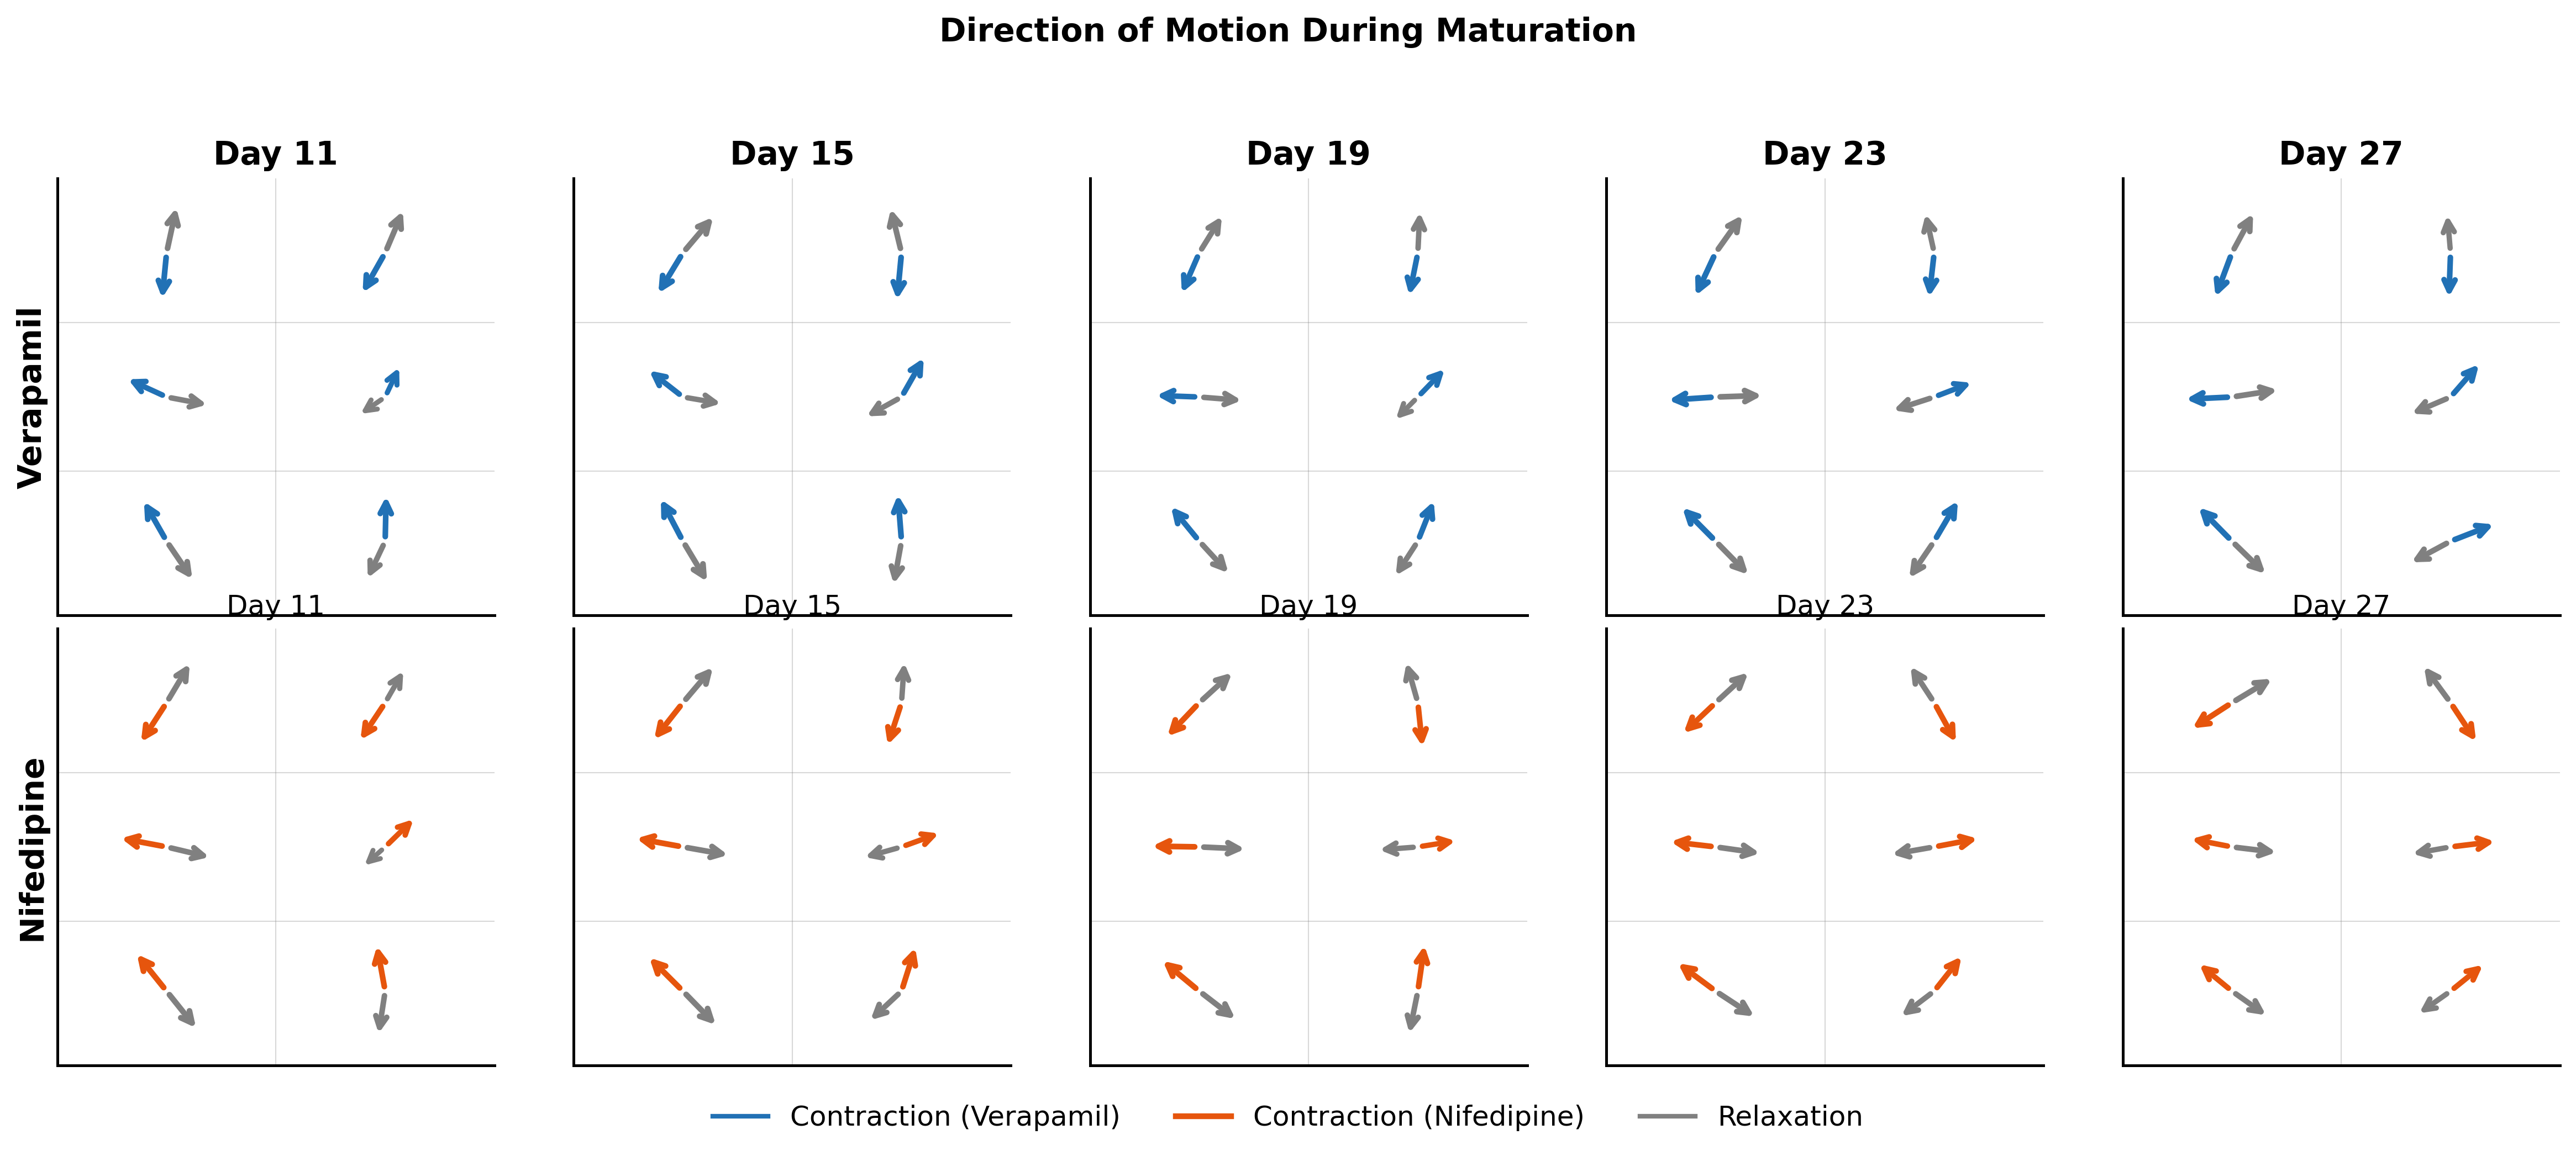

Saved: fig_direction_maturation.png


In [ ]:
#!/usr/bin/env python3
"""Direction arrows for maturation data - visualize only."""
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import warnings
warnings.filterwarnings('ignore')

VERA = '#2171B5'
NIFE = '#E6550D'

CSV_PATH = "/raid/.../all_results.csv"
df = pd.read_csv(CSV_PATH)

regions = ['r0c0', 'r0c1', 'r1c0', 'r1c1', 'r2c0', 'r2c1']
available_rise = [f"{r}_rise_angle" for r in regions if f"{r}_rise_angle" in df.columns]
available_decay = [f"{r}_decay_angle" for r in regions if f"{r}_decay_angle" in df.columns]

df_age = df[df['age'].notna()].copy()
ages = sorted(df_age['age'].unique())

def circ_mean_deg(angles_deg):
    angles_deg = np.array(angles_deg, dtype=np.float64)
    rad = np.radians(angles_deg)
    s = np.nanmean(np.sin(rad))
    c = np.nanmean(np.cos(rad))
    return np.degrees(np.arctan2(s, c)) % 360

grid_positions = {
    'r0c0': (0.25, 0.83), 'r0c1': (0.75, 0.83),
    'r1c0': (0.25, 0.50), 'r1c1': (0.75, 0.50),
    'r2c0': (0.25, 0.17), 'r2c1': (0.75, 0.17),
}

# 2 rows (drug) x 5 columns (age)
fig, axes = plt.subplots(2, 5, figsize=(16, 7))

for drug_idx, (drug, color) in enumerate([('verapamil', VERA), ('nifedipine', NIFE)]):
    sub_drug = df_age[df_age['drug'] == drug]

    for age_idx, age in enumerate(ages):
        ax = axes[drug_idx, age_idx]
        sub = sub_drug[sub_drug['age'] == age]

        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1)
        ax.set_aspect('equal')
        ax.set_title(f'Day {int(age)}', fontsize=12)
        ax.axhline(0.33, color='gray', alpha=0.3, linewidth=0.5)
        ax.axhline(0.67, color='gray', alpha=0.3, linewidth=0.5)
        ax.axvline(0.5, color='gray', alpha=0.3, linewidth=0.5)
        ax.set_xticks([])
        ax.set_yticks([])

        if age_idx == 0:
            ax.set_ylabel(drug.capitalize(), fontweight='bold', fontsize=11)
        
        if drug_idx == 0:
            ax.set_title(f'Day {int(age)}', fontsize=14, fontweight='bold')
        if age_idx == 0:
            ax.set_ylabel(drug.capitalize(), fontweight='bold', fontsize=14)

        
        for phase_name, phase_cols, arrow_color in [
            ('rise', available_rise, color),
            ('decay', available_decay, 'gray'),
        ]:
            for col, (region, (gx, gy)) in zip(phase_cols, grid_positions.items()):
                vals = sub[col].dropna().values
                if len(vals) == 0:
                    continue
                mean_angle = circ_mean_deg(vals)

                R_col = f"{region}_{phase_name}_R"
                R_val = sub[R_col].mean() if R_col in sub.columns else 0.5

                rad = np.radians(mean_angle)
                arrow_len = 0.12 * max(R_val, 0.1)
                dx = arrow_len * np.cos(rad)
                dy = arrow_len * np.sin(rad)

                ax.annotate('', xy=(gx + dx, gy + dy), xytext=(gx, gy),
                            arrowprops=dict(arrowstyle='->', color=arrow_color,
                                           lw=1.5 + R_val))

fig.legend(handles=[
    Line2D([0], [0], color=VERA, lw=2, label='Contraction (Verapamil)'),
    Line2D([0], [0], color=NIFE, lw=2.5, label='Contraction (Nifedipine)'),
    Line2D([0], [0], color='gray', lw=2, label='Relaxation'),
], loc='lower center', ncol=3, fontsize=12, frameon=False)


plt.suptitle('Direction of Motion During Maturation',
             fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0.05, 1, 0.93])
plt.savefig("fig_direction_maturation.png", dpi=300)
plt.show()
print("Saved: fig_direction_maturation.png")

Creating Figure 2: Velocity...


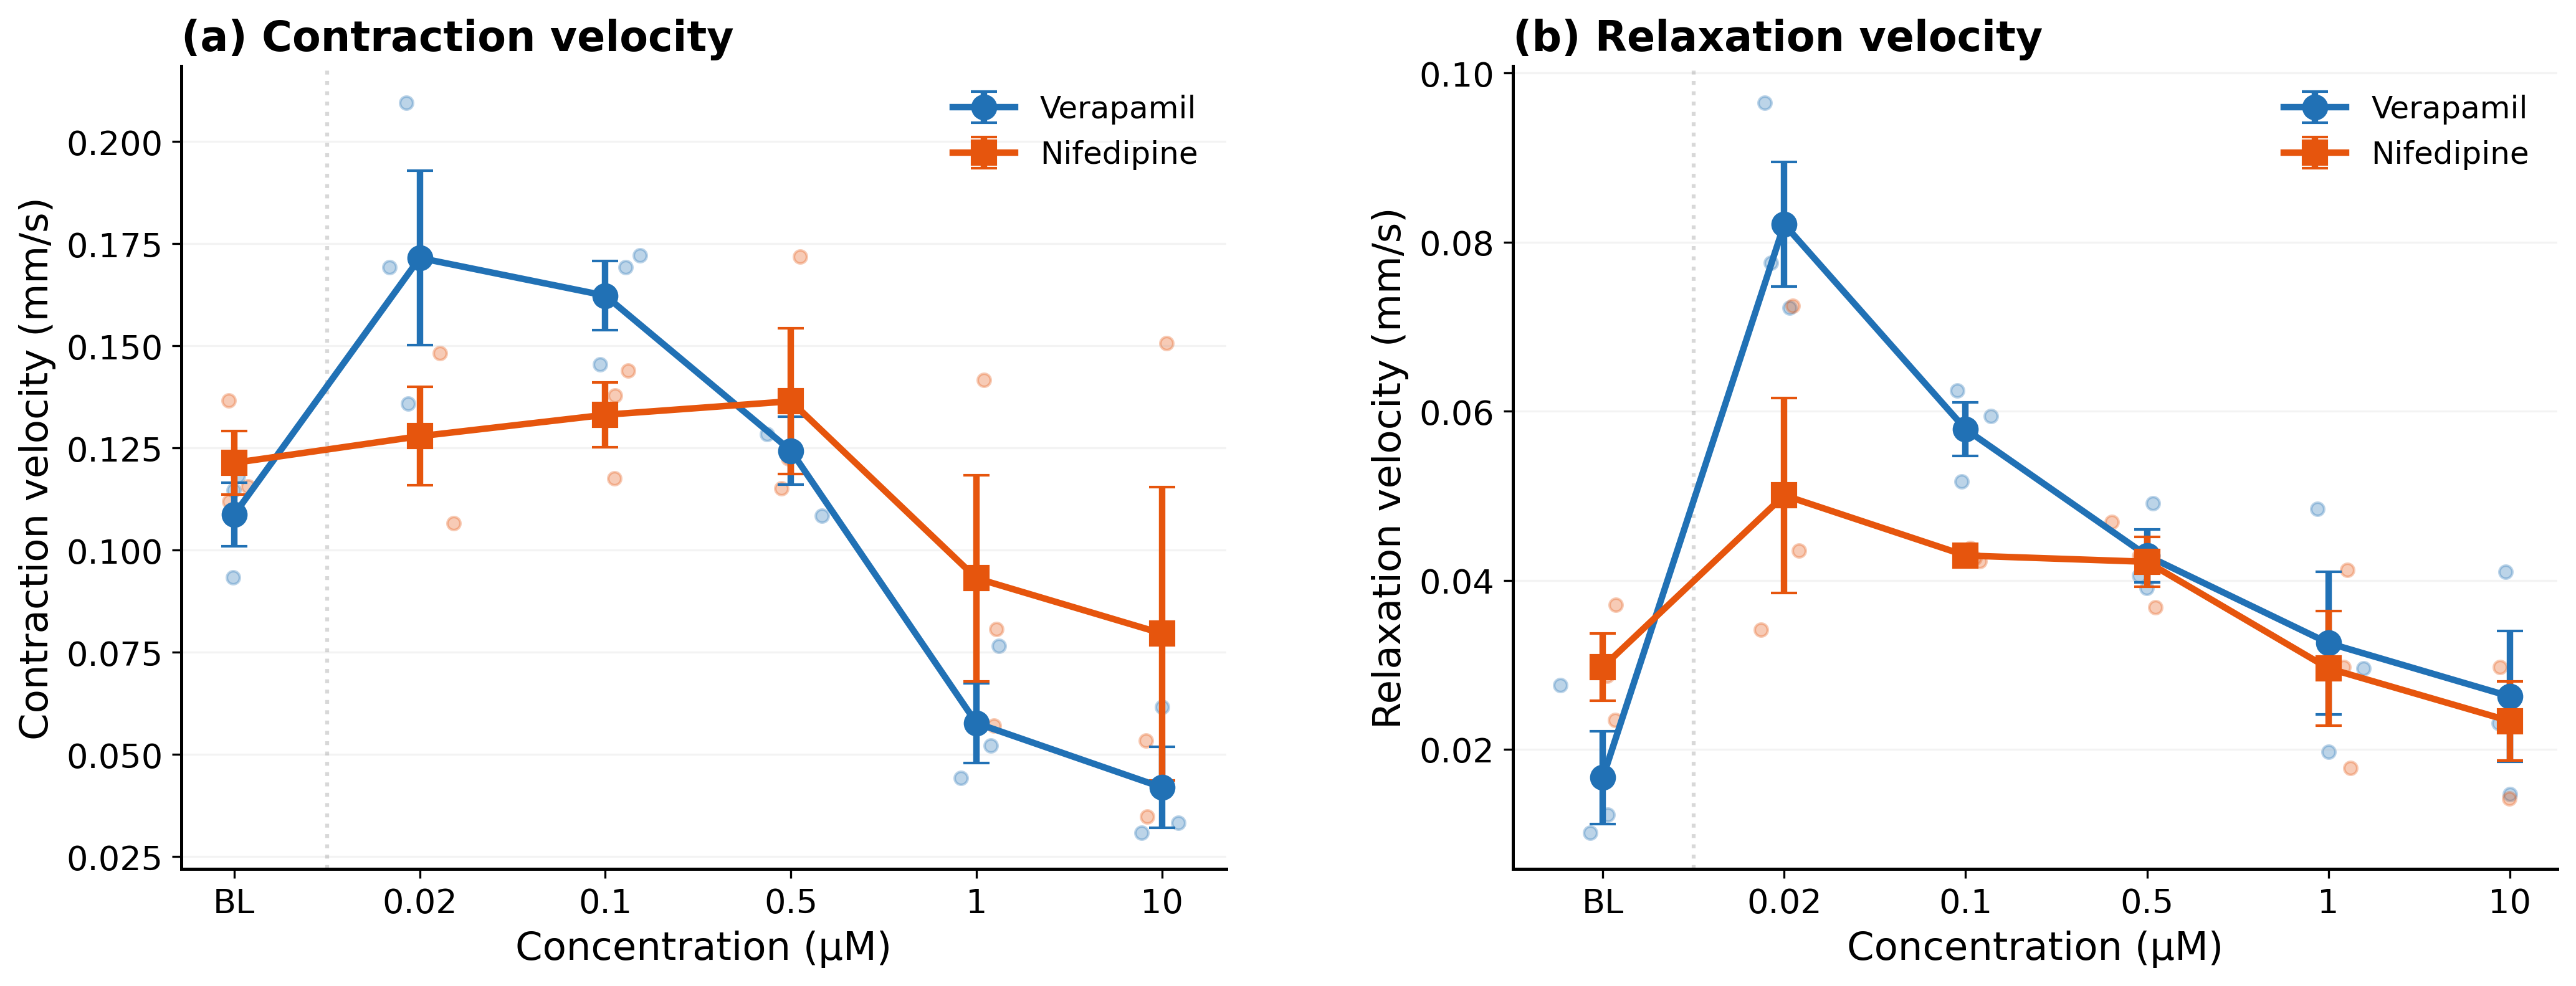

Saved fig2. slope diff contr p=0.0093, relax p=0.0137

Creating Figure 3: Direction spread vs maturation...


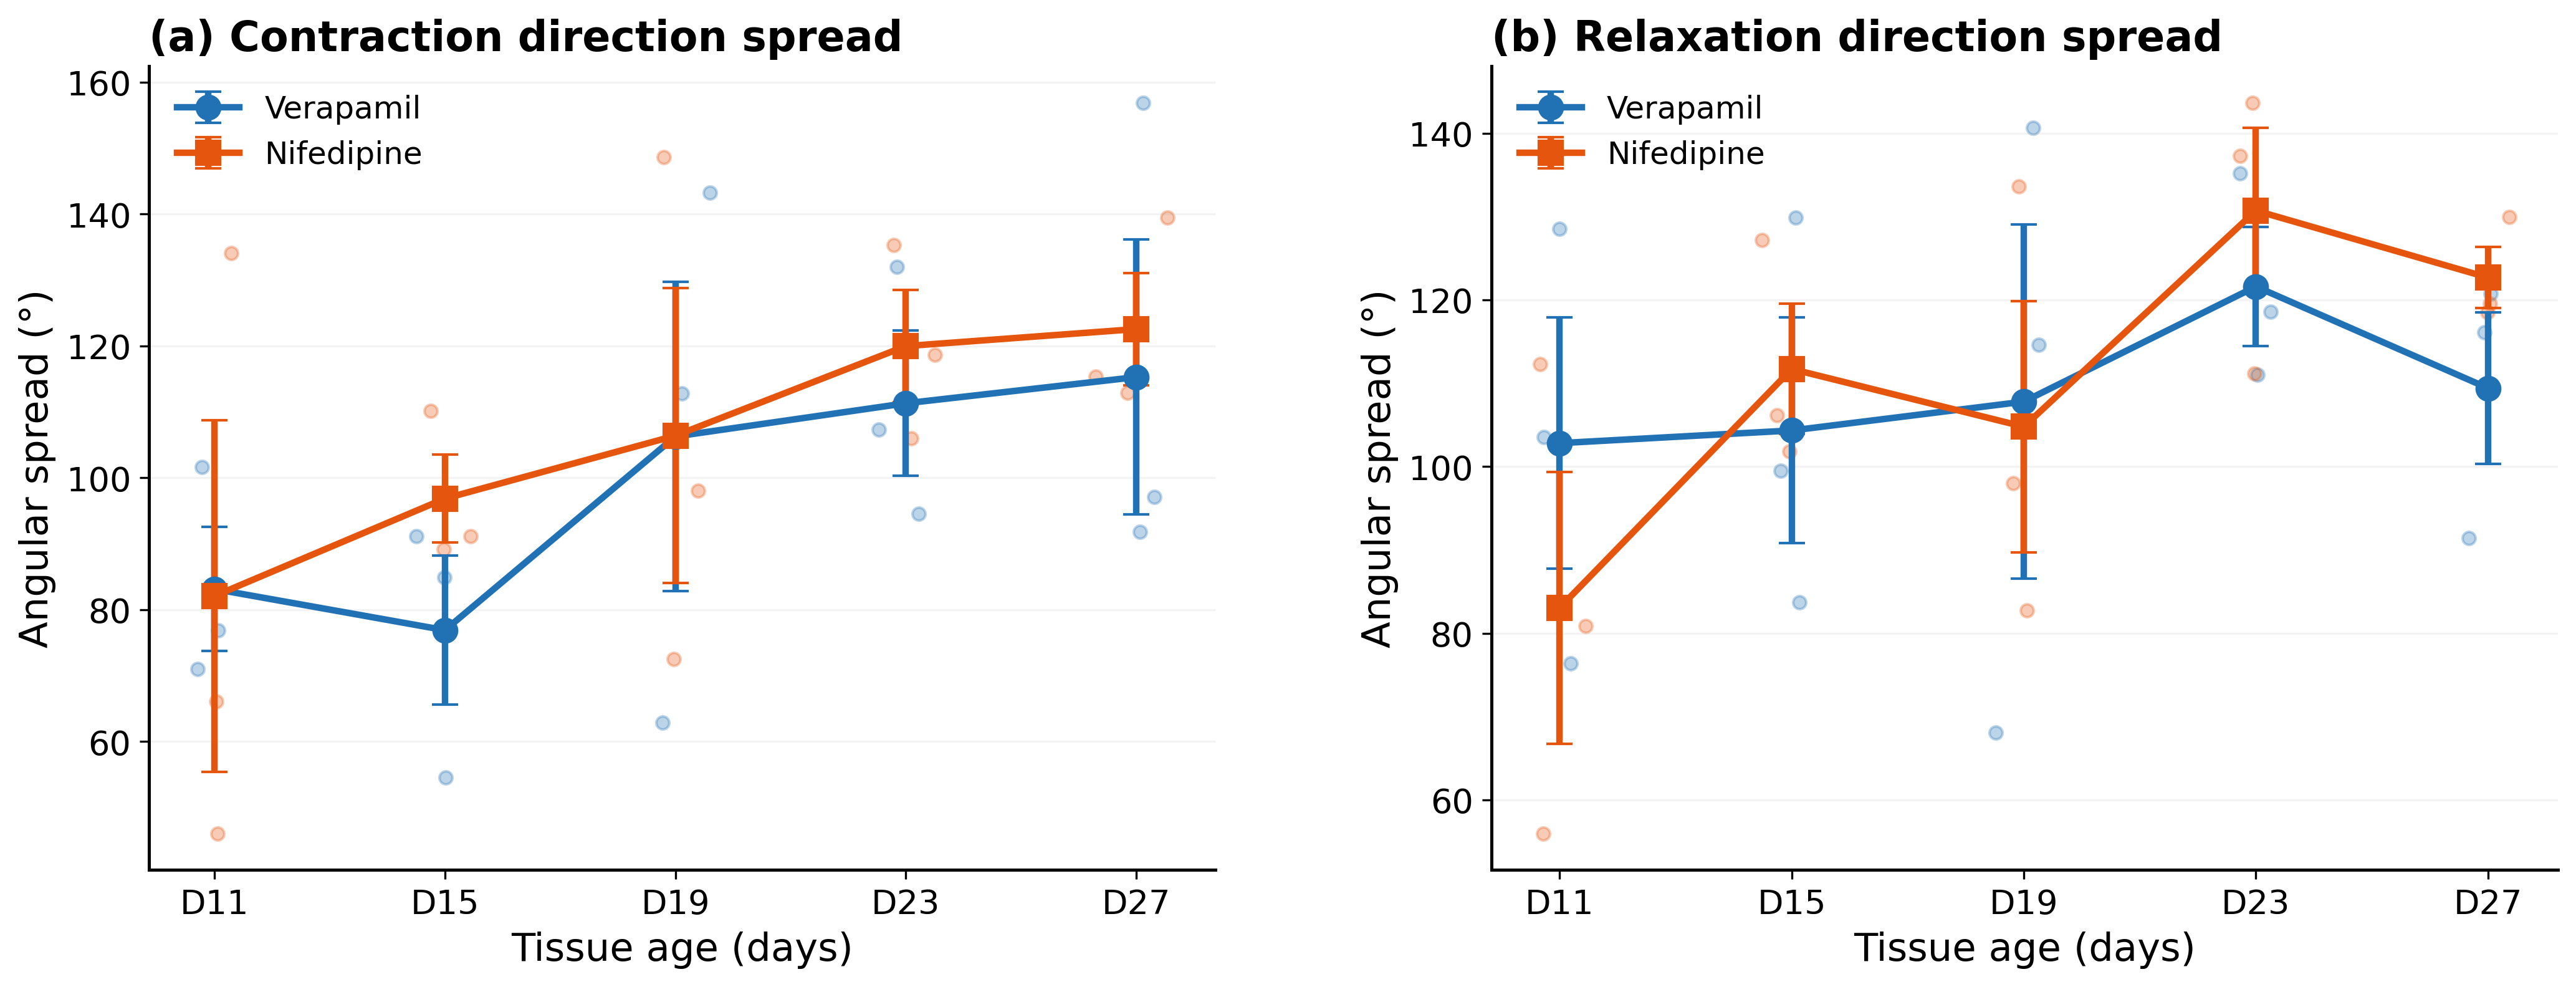

Saved fig3.

Creating Figure 4: Spatial...


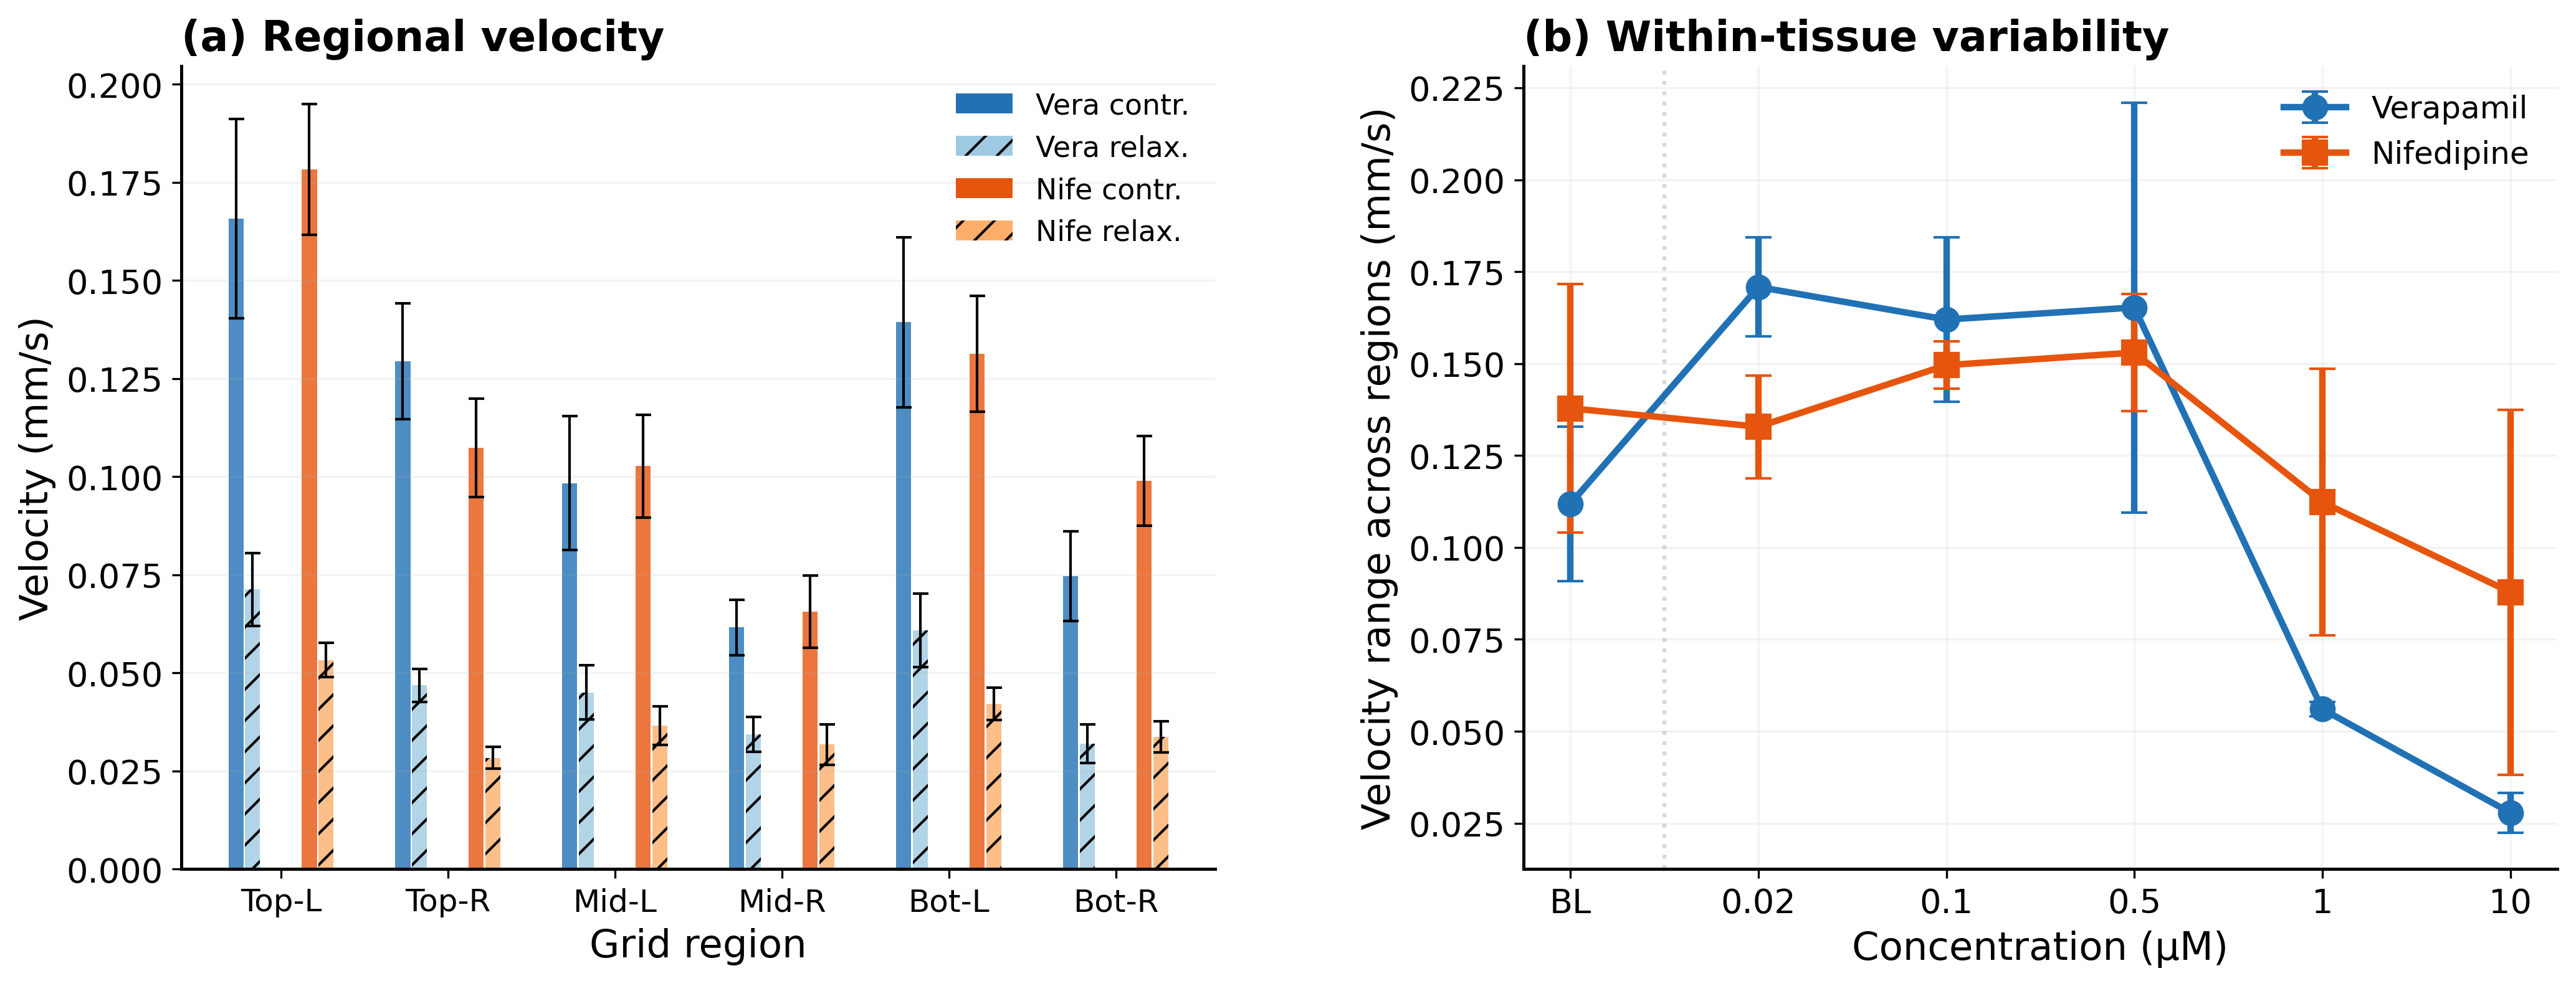

Saved fig4.

  ALL STATS FOR PAPER TEXT

Contraction slope diff: p = 0.0093
Relaxation slope diff:  p = 0.0137
  vera Contr vs conc: r = -0.88, p = 0.0000
  vera Relax vs conc: r = -0.87, p = 0.0000
  nife Contr vs conc: r = -0.47, p = 0.0765
  nife Relax vs conc: r = -0.69, p = 0.0045

  Contraction spread vs age (overall): r = 0.54, p = 0.002
  Contraction spread vs age (vera): r = 0.52, p = 0.045
  Contraction spread vs age (nife): r = 0.55, p = 0.035
  Relaxation spread vs age (overall): r = 0.41, p = 0.025
  Relaxation spread vs age (vera): r = 0.20, p = 0.483
  Relaxation spread vs age (nife): r = 0.59, p = 0.021

  Regional Kruskal: p = 2.0e-04
  vera variability vs dose: r = -0.84, p = 0.0001
  nife variability vs dose: r = -0.23, p = 0.4114

  Median velocity ratio: 2.7x
  Rise > Decay Wilcoxon: p = 1.9e-09

  vera Contr vs age: r = -0.31, p = 0.268
  vera Relax vs age: r = -0.15, p = 0.587
  nife Contr vs age: r = 0.57, p = 0.027
  nife Relax vs age: r = 0.51, p = 0.051


In [ ]:
#!/usr/bin/env python3
"""
Paper figures v8 - CLEAN, large fonts, minimal annotations.
Fig 2 (1×2): Contraction vel vs conc + Relaxation vel vs conc
Fig 3 (1×2): Contraction direction spread vs age + Relaxation direction spread vs age
Fig 4 (1×2): Regional velocity + Variability vs dose
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 14,
    'axes.labelsize': 15,
    'axes.titlesize': 16,
    'xtick.labelsize': 13,
    'ytick.labelsize': 13,
    'legend.fontsize': 12,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 1.2,
})

VERA = '#2171B5'
NIFE = '#E6550D'
VERA_LIGHT = '#9ECAE1'
NIFE_LIGHT = '#FDAE6B'

CSV_PATH = "/raid/.../all_results.csv"
df = pd.read_csv(CSV_PATH)

regions = ['r0c0', 'r0c1', 'r1c0', 'r1c1', 'r2c0', 'r2c1']

for phase in ['rise', 'decay']:
    vel_cols = [f"r{r}c{c}_{phase}_vel_mm_s" for r in range(3) for c in range(2)]
    vel_cols = [c for c in vel_cols if c in df.columns]
    df[f'mean_{phase}_vel'] = df[vel_cols].mean(axis=1)
    vals = df[vel_cols]
    df[f'{phase}_vel_range'] = vals.max(axis=1) - vals.min(axis=1)

df['vel_ratio'] = df['mean_rise_vel'] / df['mean_decay_vel'].replace(0, np.nan)

# Direction spread
def circ_std_deg(angles_deg):
    angles_deg = np.array(angles_deg, dtype=np.float64)
    rad = np.radians(angles_deg)
    R = np.sqrt(np.nanmean(np.cos(rad))**2 + np.nanmean(np.sin(rad))**2)
    if R > 1: R = 1.0
    if R < 1e-10: return 180.0
    return np.degrees(np.sqrt(-2 * np.log(R)))

for phase in ['rise', 'decay']:
    angle_cols = [f"{r}_{phase}_angle" for r in regions if f"{r}_{phase}_angle" in df.columns]
    if angle_cols:
        spreads = []
        for _, row in df.iterrows():
            vals = row[angle_cols].dropna().values
            vals = np.array(vals, dtype=np.float64)
            spreads.append(circ_std_deg(vals) if len(vals) >= 2 else np.nan)
        df[f'{phase}_angle_spread'] = spreads

df_conc = df[(df['conc'].notna()) & (df['conc'] > 0)].copy()
df_baseline = df[df['conc'] == 0].copy()
df_bl_V = df_baseline[df_baseline['case_name'].str.startswith('V')]
df_bl_N = df_baseline[df_baseline['case_name'].str.startswith('N')]
df_age = df[df['age'].notna()].copy()

conc_labels = ['BL', '0.02', '0.1', '0.5', '1', '10']
conc_values = [0.02, 0.1, 0.5, 1.0, 10.0]
ages = sorted(df_age['age'].unique())
age_labels = [f'D{int(a)}' for a in ages]


# ═══════════════════════════════════
# Helpers
# ═══════════════════════════════════
def dose_plot(ax, col, ylabel, show_legend=False):
    for drug, color, marker, bl_df in [
        ('verapamil', VERA, 'o', df_bl_V),
        ('nifedipine', NIFE, 's', df_bl_N),
    ]:
        sub = df_conc[df_conc['drug'] == drug]
        all_means, all_sems, all_x = [], [], []

        bl_vals = bl_df[col].dropna()
        if len(bl_vals) > 0:
            all_x.append(0)
            all_means.append(bl_vals.mean())
            all_sems.append(bl_vals.std() / np.sqrt(len(bl_vals)) if len(bl_vals) > 1 else 0)
            jitter = np.random.normal(0, 0.08, len(bl_vals))
            ax.scatter(np.zeros(len(bl_vals)) + jitter, bl_vals,
                       color=color, alpha=0.3, s=25, zorder=1)

        for i, c in enumerate(conc_values):
            vals = sub[sub['conc'] == c][col].dropna()
            if len(vals) > 0:
                all_x.append(i + 1)
                all_means.append(vals.mean())
                all_sems.append(vals.std() / np.sqrt(len(vals)) if len(vals) > 1 else 0)
                jitter = np.random.normal(0, 0.08, len(vals))
                ax.scatter(np.full(len(vals), i + 1) + jitter, vals,
                           color=color, alpha=0.3, s=25, zorder=1)

        ax.errorbar(all_x, all_means, yerr=all_sems,
                    marker=marker, color=color, capsize=5, linewidth=2.5,
                    markersize=9, label=drug.capitalize(), zorder=3)

    ax.set_xticks(range(len(conc_labels)))
    ax.set_xticklabels(conc_labels)
    ax.set_xlabel('Concentration (μM)')
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.15, axis='y')
    ax.axvline(0.5, color='gray', linestyle=':', alpha=0.3)
    if show_legend:
        ax.legend(frameon=False, loc='best')


def age_plot(ax, col, ylabel, show_legend=False):
    age_x = np.arange(len(ages))
    for drug, color, marker in [('verapamil', VERA, 'o'), ('nifedipine', NIFE, 's')]:
        sub = df_age[df_age['drug'] == drug]
        means, sems = [], []
        for age in ages:
            vals = sub[sub['age'] == age][col].dropna()
            means.append(vals.mean() if len(vals) > 0 else np.nan)
            sems.append(vals.std() / np.sqrt(len(vals)) if len(vals) > 1 else 0)
        ax.errorbar(age_x, means, yerr=sems,
                    marker=marker, color=color, capsize=5, linewidth=2.5,
                    markersize=9, label=drug.capitalize(), zorder=3)
        for i, age in enumerate(ages):
            pts = sub[sub['age'] == age][col].dropna()
            jitter = np.random.normal(0, 0.08, len(pts))
            ax.scatter(np.full(len(pts), i) + jitter, pts,
                       color=color, alpha=0.3, s=25, zorder=1)
    ax.set_xticks(age_x)
    ax.set_xticklabels(age_labels)
    ax.set_xlabel('Tissue age (days)')
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.15, axis='y')
    if show_legend:
        ax.legend(frameon=False, loc='best')


# ═══════════════════════════════════════════════
#  FIGURE 2: VELOCITY 1×2
# ═══════════════════════════════════════════════
print("Creating Figure 2: Velocity...")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Contraction vel vs conc
ax = axes[0]
dose_plot(ax, 'mean_rise_vel', 'Contraction velocity (mm/s)', show_legend=True)
ax.set_title('(a) Contraction velocity', loc='left', fontweight='bold')

# compute slope diff for printing
v_sub = df_conc[df_conc['drug'] == 'verapamil'].dropna(subset=['mean_rise_vel'])
n_sub = df_conc[df_conc['drug'] == 'nifedipine'].dropna(subset=['mean_rise_vel'])
sv, _, _, _, sev = stats.linregress(np.log10(v_sub['conc']), v_sub['mean_rise_vel'])
sn, _, _, _, sen = stats.linregress(np.log10(n_sub['conc']), n_sub['mean_rise_vel'])
z = (sv - sn) / np.sqrt(sev**2 + sen**2)
p_diff_contr = 2 * (1 - stats.norm.cdf(abs(z)))

# (b) Relaxation vel vs conc
ax = axes[1]
dose_plot(ax, 'mean_decay_vel', 'Relaxation velocity (mm/s)', show_legend=True)
ax.set_title('(b) Relaxation velocity', loc='left', fontweight='bold')

v_sub = df_conc[df_conc['drug'] == 'verapamil'].dropna(subset=['mean_decay_vel'])
n_sub = df_conc[df_conc['drug'] == 'nifedipine'].dropna(subset=['mean_decay_vel'])
sv, _, _, _, sev = stats.linregress(np.log10(v_sub['conc']), v_sub['mean_decay_vel'])
sn, _, _, _, sen = stats.linregress(np.log10(n_sub['conc']), n_sub['mean_decay_vel'])
z = (sv - sn) / np.sqrt(sev**2 + sen**2)
p_diff_relax = 2 * (1 - stats.norm.cdf(abs(z)))

plt.tight_layout(w_pad=4)
plt.savefig("fig2_velocity.png", dpi=300)
plt.savefig("fig2_velocity.pdf")
plt.show()
print(f"Saved fig2. slope diff contr p={p_diff_contr:.4f}, relax p={p_diff_relax:.4f}")


# ═══════════════════════════════════════════════
#  FIGURE 3: DIRECTION SPREAD vs AGE 1×2
# ═══════════════════════════════════════════════
print("\nCreating Figure 3: Direction spread vs maturation...")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Contraction direction spread vs age
ax = axes[0]
age_plot(ax, 'rise_angle_spread', 'Angular spread (°)', show_legend=True)
ax.set_title('(a) Contraction direction spread', loc='left', fontweight='bold')

# (b) Relaxation direction spread vs age
ax = axes[1]
age_plot(ax, 'decay_angle_spread', 'Angular spread (°)', show_legend=True)
ax.set_title('(b) Relaxation direction spread', loc='left', fontweight='bold')

plt.tight_layout(w_pad=4)
plt.savefig("fig3_direction_spread.png", dpi=300)
plt.savefig("fig3_direction_spread.pdf")
plt.show()
print("Saved fig3.")


# ═══════════════════════════════════════════════
#  FIGURE 4: SPATIAL 1×2
# ═══════════════════════════════════════════════
print("\nCreating Figure 4: Spatial...")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# (a) Regional velocity by drug
ax = axes[0]
region_names_short = ['Top-L', 'Top-R', 'Mid-L', 'Mid-R', 'Bot-L', 'Bot-R']
region_codes = ['r0c0', 'r0c1', 'r1c0', 'r1c1', 'r2c0', 'r2c1']
x = np.arange(len(region_codes))

for drug_idx, (drug, color_rise, color_decay) in enumerate([
    ('verapamil', VERA, VERA_LIGHT),
    ('nifedipine', NIFE, NIFE_LIGHT),
]):
    sub = df_conc[df_conc['drug'] == drug]
    offset = -0.22 if drug_idx == 0 else 0.22
    for phase, color, hatch in [('rise', color_rise, None), ('decay', color_decay, '//')]:
        means, sems = [], []
        for rc in region_codes:
            col = f"{rc}_{phase}_vel_mm_s"
            if col in sub.columns:
                vals = sub[col].dropna()
                means.append(vals.mean())
                sems.append(vals.std() / np.sqrt(len(vals)) if len(vals) > 1 else 0)
            else:
                means.append(0); sems.append(0)
        phase_offset = -0.05 if phase == 'rise' else 0.05
        ax.bar(x + offset + phase_offset, means, width=0.09, yerr=sems,
               capsize=3, color=color, alpha=0.8, hatch=hatch,
               error_kw={'linewidth': 1})

ax.set_xticks(x)
ax.set_xticklabels(region_names_short, fontsize=12)
ax.set_xlabel('Grid region')
ax.set_ylabel('Velocity (mm/s)')
ax.set_title('(a) Regional velocity', loc='left', fontweight='bold')

legend_elements = [
    Patch(facecolor=VERA, label='Vera contr.'),
    Patch(facecolor=VERA_LIGHT, hatch='//', label='Vera relax.'),
    Patch(facecolor=NIFE, label='Nife contr.'),
    Patch(facecolor=NIFE_LIGHT, hatch='//', label='Nife relax.'),
]
ax.legend(handles=legend_elements, frameon=False, fontsize=11, loc='upper right')
ax.grid(True, alpha=0.15, axis='y')

# (b) Within-tissue variability vs dose
ax = axes[1]
for drug, color, marker, bl_df in [
    ('verapamil', VERA, 'o', df_bl_V),
    ('nifedipine', NIFE, 's', df_bl_N),
]:
    sub = df_conc[df_conc['drug'] == drug].dropna(subset=['rise_vel_range'])
    all_x, all_means, all_sems = [], [], []

    bl_vals = bl_df['rise_vel_range'].dropna() if 'rise_vel_range' in bl_df.columns else pd.Series()
    if len(bl_vals) > 0:
        all_x.append(0)
        all_means.append(bl_vals.mean())
        all_sems.append(bl_vals.std() / np.sqrt(len(bl_vals)) if len(bl_vals) > 1 else 0)

    for i, c in enumerate(conc_values):
        vals = sub[sub['conc'] == c]['rise_vel_range'].dropna()
        if len(vals) > 0:
            all_x.append(i + 1)
            all_means.append(vals.mean())
            all_sems.append(vals.std() / np.sqrt(len(vals)) if len(vals) > 1 else 0)

    ax.errorbar(all_x, all_means, yerr=all_sems,
                marker=marker, color=color, capsize=5, linewidth=2.5,
                markersize=9, label=drug.capitalize())

ax.set_xticks(range(len(conc_labels)))
ax.set_xticklabels(conc_labels)
ax.axvline(0.5, color='gray', linestyle=':', alpha=0.3)
ax.set_xlabel('Concentration (μM)')
ax.set_ylabel('Velocity range across regions (mm/s)')
ax.set_title('(b) Within-tissue variability', loc='left', fontweight='bold')
ax.legend(frameon=False)
ax.grid(True, alpha=0.15)

plt.tight_layout(w_pad=4)
plt.savefig("fig4_spatial.png", dpi=300)
plt.savefig("fig4_spatial.pdf")
plt.show()
print("Saved fig4.")


# ═══════════════════════════════════════════════
# Print all stats for paper text
# ═══════════════════════════════════════════════
print("\n" + "=" * 60)
print("  ALL STATS FOR PAPER TEXT")
print("=" * 60)

# Velocity
print(f"\nContraction slope diff: p = {p_diff_contr:.4f}")
print(f"Relaxation slope diff:  p = {p_diff_relax:.4f}")

for drug in ['verapamil', 'nifedipine']:
    for col, label in [('mean_rise_vel', 'Contr'), ('mean_decay_vel', 'Relax')]:
        sub = df_conc[df_conc['drug'] == drug].dropna(subset=[col])
        _, _, r_val, p_val, _ = stats.linregress(np.log10(sub['conc']), sub[col])
        print(f"  {drug[:4]} {label} vs conc: r = {r_val:.2f}, p = {p_val:.4f}")

# Direction spread vs age
print()
for phase, label in [('rise', 'Contraction'), ('decay', 'Relaxation')]:
    col = f'{phase}_angle_spread'
    # Overall
    valid = df_age[['age', col]].dropna()
    if len(valid) >= 4:
        r, p = stats.spearmanr(valid['age'], valid[col])
        print(f"  {label} spread vs age (overall): r = {r:.2f}, p = {p:.3f}")
    # Per drug
    for drug in ['verapamil', 'nifedipine']:
        sub = df_age[df_age['drug'] == drug][['age', col]].dropna()
        if len(sub) >= 4:
            r, p = stats.spearmanr(sub['age'], sub[col])
            print(f"  {label} spread vs age ({drug[:4]}): r = {r:.2f}, p = {p:.3f}")

# Regional
rise_top = df_conc[['r0c0_rise_vel_mm_s', 'r0c1_rise_vel_mm_s']].mean(axis=1)
rise_mid = df_conc[['r1c0_rise_vel_mm_s', 'r1c1_rise_vel_mm_s']].mean(axis=1)
rise_bot = df_conc[['r2c0_rise_vel_mm_s', 'r2c1_rise_vel_mm_s']].mean(axis=1)
_, p_reg = stats.kruskal(rise_top.dropna(), rise_mid.dropna(), rise_bot.dropna())
print(f"\n  Regional Kruskal: p = {p_reg:.1e}")

# Variability vs dose
for drug in ['verapamil', 'nifedipine']:
    sub = df_conc[df_conc['drug'] == drug].dropna(subset=['rise_vel_range'])
    r_sp, p_sp = stats.spearmanr(np.log10(sub['conc']), sub['rise_vel_range'])
    print(f"  {drug[:4]} variability vs dose: r = {r_sp:.2f}, p = {p_sp:.4f}")

# Velocity ratio + rise > decay
median_ratio = df_conc['vel_ratio'].median()
_, p_wr = stats.wilcoxon(df_conc['mean_rise_vel'], df_conc['mean_decay_vel'])
print(f"\n  Median velocity ratio: {median_ratio:.2f}x")
print(f"\n  Median velocity ratio: {median_ratio:.1f}x")
print(f"  Rise > Decay Wilcoxon: p = {p_wr:.1e}")

# Age velocity
print()
for drug in ['verapamil', 'nifedipine']:
    for col, label in [('mean_rise_vel', 'Contr'), ('mean_decay_vel', 'Relax')]:
        sub = df_age[df_age['drug'] == drug][['age', col]].dropna()
        if len(sub) >= 4:
            r, p = stats.spearmanr(sub['age'], sub[col])
            print(f"  {drug[:4]} {label} vs age: r = {r:.2f}, p = {p:.3f}")